# Matriz de confusión: guía docente exhaustiva, desde cero hasta la evaluación profesional

**Curso de Machine Learning · Clasificación binaria y multiclase · Google Colab**

**Objetivo:** comprender **qué está contando exactamente cada celda de una matriz de confusión**, quién define la clase positiva, cómo cambian las cifras al variar el umbral y cómo juzgar si un clasificador resulta útil según el problema. Cada *chunk* ejecutable tiene una explicación posterior sobre el significado del resultado, sus unidades, su cálculo y sus límites.

**Ruta:** intuición → matriz manual → fórmulas → base de datos sintética → regresión logística → curvas/umbrales → desbalance y costos → comparación en validación cruzada → interpretación multiclase → conclusiones. La base se crea automáticamente. No hay que subir CSV ni utilizar Drive.

> **Precaución:** los 600 estudiantes son simulados, no corresponden a personas reales y no justifican decisiones académicas individuales. Los ejemplos médicos, industriales y académicos son ilustrativos.

## 1. ¿Qué es exactamente una matriz de confusión y cuándo se utiliza?

Una **matriz de confusión** es una tabla que cruza **clases reales** con **clases predichas**. Se usa después de que un clasificador predice etiquetas en datos conocidos (idealmente de prueba no usados para ajustar el modelo). En regresión logística, la salida inicial es una **probabilidad**; al aplicar un umbral, por ejemplo 0,50, obtenemos una clase y podemos construir la matriz.

La matriz no sirve para evaluar directamente una regresión cuyo objetivo es continuo. Para evaluar predicciones de notas numéricas utilizamos MAE, RMSE o R²; para predecir **aprobó (1) / no aprobó (0)** corresponde evaluar clasificación.

### Convención empleada en todo el notebook

| | **Predijo 0 (negativo)** | **Predijo 1 (positivo)** |
|---|---:|---:|
| **Real 0 (negativo)** | **VN / TN**: verdadero negativo | **FP**: falso positivo |
| **Real 1 (positivo)** | **FN**: falso negativo | **VP / TP**: verdadero positivo |

**Positivo no significa bueno**: es simplemente la clase que definimos como `1`. Si `1=aprobó`, VP es un estudiante que aprobó y que fue predicho como aprobado. En detección de fallas, si `1=falla`, VP sería una falla detectada. El orden de filas y columnas se fija expresamente con `labels=[0,1]`.

## 2. Preparar Python y fijar la reproducibilidad

**Antes de ejecutar:** instaladas en Colab están `numpy`, `pandas`, `matplotlib`, `seaborn` y `scikit-learn`. Una semilla fija permite reproducir sorteos: no implica que el modelo sea más exacto ni evita por sí sola sesgos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, classification_report, balanced_accuracy_score,
    roc_auc_score, average_precision_score, precision_recall_curve, roc_curve)
SEED=42
rng=np.random.default_rng(SEED)
print('Semilla reproducible:', SEED)
print('Bibliotecas listas para trabajar')

Semilla reproducible: 42
Bibliotecas listas para trabajar


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> La salida **42** identifica la semilla usada para generar números pseudoaleatorios. No son 42 estudiantes ni 42 iteraciones. Este código **todavía no entrena ningún modelo**: importa herramientas y fija la configuración común.

## 3. Ejemplo manual con 20 estudiantes: contar antes de automatizar

Supongamos que se conocen las clases reales de 20 estudiantes y que un modelo hace 20 predicciones. En este ejemplo artificial establecemos intencionalmente 8 VN, 3 FP, 2 FN y 7 VP. **Primero contamos; después calculamos métricas.**

In [2]:
y_real_manual=np.array([0]*11+[1]*9)
y_pred_manual=np.array([0]*8+[1]*3+[0]*2+[1]*7)
tabla_manual=pd.DataFrame({'Estudiante':np.arange(1,21),'Real':y_real_manual,'Predicha':y_pred_manual})
tabla_manual['Resultado']=np.select([
 (tabla_manual.Real==0)&(tabla_manual.Predicha==0),
 (tabla_manual.Real==0)&(tabla_manual.Predicha==1),
 (tabla_manual.Real==1)&(tabla_manual.Predicha==0)], ['VN','FP','FN'],default='VP')
display(tabla_manual)
print('Conteo de resultados:');print(tabla_manual['Resultado'].value_counts().reindex(['VN','FP','FN','VP']))

,Estudiante,Real,Predicha,Resultado
0,1,0,0,VN
1,2,0,0,VN
2,3,0,0,VN
3,4,0,0,VN
4,5,0,0,VN
5,6,0,0,VN
6,7,0,0,VN
7,8,0,0,VN
8,9,0,1,FP
9,10,0,1,FP


Conteo de resultados:
Resultado
VN    8
FP    3
FN    2
VP    7
Name: count, dtype: int64


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> Las **20 filas** son 20 predicciones distintas. Entre los **11 estudiantes reales de clase 0**, ocho fueron reconocidos como 0 y tres fueron erróneamente etiquetados 1; entre los **9 de clase 1**, siete fueron reconocidos como 1 y dos se perdieron como 0. **VN=8, FP=3, FN=2, VP=7; suma=20.** En la columna `Resultado` cada fila se asigna a una de las cuatro categorías mutuamente excluyentes.

Matriz de confusión:
[[8 3]
 [2 7]]


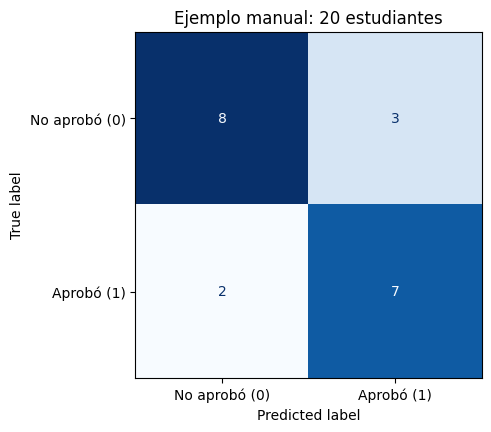

VN=8, FP=3, FN=2, VP=7, Total=20


In [3]:
matriz_manual=confusion_matrix(y_real_manual,y_pred_manual,labels=[0,1])
print('Matriz de confusión:');print(matriz_manual)
fig,ax=plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay(matriz_manual,display_labels=['No aprobó (0)','Aprobó (1)']).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
ax.set_title('Ejemplo manual: 20 estudiantes')
plt.show()
VN,FP,FN,VP=matriz_manual.ravel()
print(f'VN={VN}, FP={FP}, FN={FN}, VP={VP}, Total={matriz_manual.sum()}')

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> La matriz debe leerse **por filas reales y columnas predichas**: `[[8,3],[2,7]]`. La celda superior izquierda 8 es VN; superior derecha 3 es FP; inferior izquierda 2 es FN; inferior derecha 7 es VP. Los **15 aciertos** están en la diagonal (`8+7`). Los **5 errores** están fuera de ella (`3+2`). La gráfica no añade información nueva: representa visualmente la misma tabla.

## 4. Métricas: ¿de dónde sale cada denominador?

Una matriz de confusión contiene conteos; las métricas convierten esos conteos en proporciones. **No todas responden la misma pregunta**.

- **Exactitud / Accuracy**: del total, ¿qué proporción acertamos? `(VP+VN)/(VP+VN+FP+FN)`.
- **Precisión / Precision de la clase 1**: de quienes predijimos positivos, ¿cuántos realmente son positivos? `VP/(VP+FP)`.
- **Sensibilidad / Recall / TPR**: de los positivos reales, ¿cuántos encontramos? `VP/(VP+FN)`.
- **Especificidad / TNR**: de los negativos reales, ¿cuántos identificamos? `VN/(VN+FP)`.
- **FPR**: entre negativos reales, ¿qué proporción confundimos como positiva? `FP/(FP+VN)`.
- **FNR**: entre positivos reales, ¿qué proporción pasamos por alto? `FN/(FN+VP)`.
- **F1**: media armónica de precisión y recall: `2·precision·recall/(precision+recall)`.
- **NPV (valor predictivo negativo)**: entre los predichos 0, ¿qué fracción es verdaderamente 0? `VN/(VN+FN)`.

El denominador de **precision** se refiere a **predicciones positivas**. El de **recall** se refiere a **positivos reales**: esta diferencia explica por qué pueden cambiar de manera opuesta.

In [4]:
accuracy_manual=(VP+VN)/(VP+VN+FP+FN)
precision_manual=VP/(VP+FP)
recall_manual=VP/(VP+FN)
especificidad_manual=VN/(VN+FP)
fpr_manual=FP/(FP+VN)
fnr_manual=FN/(FN+VP)
npv_manual=VN/(VN+FN)
f1_manual=2*precision_manual*recall_manual/(precision_manual+recall_manual)
print(pd.Series({'Accuracy':accuracy_manual,'Precision':precision_manual,'Recall':recall_manual,
 'Especificidad':especificidad_manual,'FPR':fpr_manual,'FNR':fnr_manual,'NPV':npv_manual,'F1':f1_manual}).round(4))

Accuracy         0.7500
Precision        0.7000
Recall           0.7778
Especificidad    0.7273
FPR              0.2727
FNR              0.2222
NPV              0.8000
F1               0.7368
dtype: float64


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> **Accuracy=0,7500** porque `(8+7)/20=15/20`. **Precision=0,7000** porque `7/(7+3)=7/10`: siete de diez predicciones positivas eran correctas. **Recall=0,7778** porque `7/(7+2)=7/9`: detectamos siete de nueve positivos reales. **Especificidad=0,7273** porque `8/11`; **FPR=0,2727** porque `3/11`; por eso especificidad + FPR = 1. **FNR=0,2222** porque `2/9`; por eso recall + FNR = 1. **NPV=0,8000** porque `8/(8+2)`. **F1≈0,7368**, obtenida como media armónica de 0,70 y 0,7778. Estas métricas describen este ejemplo de 20, no una población general.

## 5. Comprobar cálculos manuales con Scikit-learn

Es importante que los estudiantes verifiquen que las fórmulas hechas a mano coinciden con funciones de biblioteca. Las funciones no «adivinan»: reciben etiquetas reales y predichas y cuentan las cuatro situaciones.

In [5]:
print('Accuracy sklearn:',round(accuracy_score(y_real_manual,y_pred_manual),4))
print('Precision sklearn:',round(precision_score(y_real_manual,y_pred_manual),4))
print('Recall sklearn:',round(recall_score(y_real_manual,y_pred_manual),4))
print('F1 sklearn:',round(f1_score(y_real_manual,y_pred_manual),4))
print('\nReporte por clase:')
print(classification_report(y_real_manual,y_pred_manual,target_names=['No aprobó','Aprobó'],digits=4,zero_division=0))

Accuracy sklearn: 0.75
Precision sklearn: 0.7
Recall sklearn: 0.7778
F1 sklearn: 0.7368

Reporte por clase:
              precision    recall  f1-score   support

   No aprobó     0.8000    0.7273    0.7619        11
      Aprobó     0.7000    0.7778    0.7368         9

    accuracy                         0.7500        20
   macro avg     0.7500    0.7525    0.7494        20
weighted avg     0.7550    0.7500    0.7506        20



> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> Los primeros cuatro valores deben coincidir exactamente con los cálculos manuales al redondear. En `classification_report`, **support** es el número de observaciones **reales** de cada clase: **11 para 0 y 9 para 1**, no el número de predicciones. El reporte trata a cada clase como «positiva» por turno: el recall de la clase 0 equivale a la especificidad de la clase 1. `macro avg` promedia métricas de clases con igual peso; `weighted avg` pondera por soporte, lo que puede ocultar un mal rendimiento en clases minoritarias.

## 6. ¿Por qué no existe una «buena matriz» universal?

Una decisión de clasificación depende del problema. En **detección de defectos** (`1 = producto defectuoso`), un FN implica dejar pasar un producto defectuoso; posiblemente sea muy costoso. En un sistema de **alertas académicas** (`1 = estudiante en riesgo`), un FP genera una alerta innecesaria, pero un FN puede impedir una intervención de apoyo. **No se escoge precisión o recall por moda:** se escogen en función del impacto de cada error y del objetivo operacional. La clase positiva debe definirse explícitamente antes de interpretar.

## 7. Construir una base de 600 estudiantes simulados

Conservamos el contexto del notebook anterior de regresión logística. La clase objetivo será `aprobo`: `0` si nota final menor que 3,0 y `1` si nota final al menos 3,0. **La nota final no se usa como predictora**, pues convertiría el ejercicio en una fuga directa de la etiqueta. Los atributos disponibles para predecir serán promedio anterior, horas de estudio, asistencia, edad, estrato y situación laboral.

Esta base fue creada para enseñanza. Las relaciones no deben extrapolarse a personas reales.

In [6]:
n=600
promedio=np.clip(rng.normal(3.35,0.62,n),1.5,5)
horas=np.clip(rng.normal(9.0,4.2,n),0,23)
asistencia=np.clip(rng.normal(79.0,12.0,n),40,100)
edad=rng.integers(17,35,n)
estrato=rng.integers(1,7,n)
trabaja=rng.binomial(1,0.38,n)
ruido=rng.normal(0,0.42,n)
nota=np.clip(-0.30+0.62*promedio+0.069*horas+0.013*asistencia-0.25*trabaja+ruido,0,5)
datos=pd.DataFrame({'promedio_anterior':promedio,'horas_estudio_semana':horas,
 'asistencia_pct':asistencia,'edad':edad,'estrato':estrato,'trabaja':trabaja,
 'nota_final':nota.round(3)})
datos['aprobo']=(datos['nota_final']>=3).astype(int)
columnas_x=['promedio_anterior','horas_estudio_semana','asistencia_pct','edad','estrato','trabaja']
print('Dimensiones:',datos.shape)
print('Distribución por clase:');print(datos.aprobo.value_counts().sort_index())
print('Proporción por clase:');print(datos.aprobo.value_counts(normalize=True).sort_index().round(4))
display(datos.head(5).round(3))

Dimensiones: (600, 8)
Distribución por clase:
aprobo
0    194
1    406
Name: count, dtype: int64
Proporción por clase:
aprobo
0    0.3233
1    0.6767
Name: proportion, dtype: float64


,promedio_anterior,horas_estudio_semana,asistencia_pct,edad,estrato,trabaja,nota_final,aprobo
0,3.539,11.165,63.130,24,1,0,2.920,0
1,2.705,6.574,73.166,28,6,0,2.453,0
2,3.815,14.353,84.043,20,3,0,4.096,1
3,3.933,6.364,77.771,22,1,0,3.332,1
4,2.140,6.326,71.193,24,6,0,3.355,1


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> `(600, 8)` significa 600 filas y 8 columnas: seis posibles predictores, la nota final y la etiqueta derivada. `value_counts()` muestra **cuántos estudiantes realmente pertenecen** a cada clase; `normalize=True` divide cada conteo entre 600. Una frecuencia de clase 1 superior a la de clase 0 produciría un punto de partida distinto para un clasificador que predijera siempre la clase mayoritaria. Una fila de `head()` es una observación, no un resumen de población. **No se ha entrenado ningún modelo todavía.**

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Lectura numérica concreta:** 194 estudiantes (32,33 %) no aprobaron y 406 (67,67 %) aprobaron. La clase 1 es mayoritaria: un modelo que siempre prediga 1 ya acertaría aproximadamente 67,67 % en la base completa. Esto anticipa por qué necesitaremos métricas por clase. La etiqueta `aprobo` depende de la nota simulada, que se excluye de los predictores para evitar fuga directa de información.

Nulos por columna:
promedio_anterior       0
horas_estudio_semana    0
asistencia_pct          0
edad                    0
estrato                 0
trabaja                 0
nota_final              0
aprobo                  0

Resumen de cuatro variables:


,promedio_anterior,horas_estudio_semana,asistencia_pct,nota_final
count,600.000,600.000,600.000,600.000
mean,3.333,8.958,77.839,3.317
std,0.602,4.104,12.070,0.632
min,1.512,0.000,43.533,1.567
25%,2.917,6.318,70.280,2.879
50%,3.337,9.042,78.170,3.296
75%,3.714,11.594,86.243,3.728
max,5.000,22.351,100.000,5.000


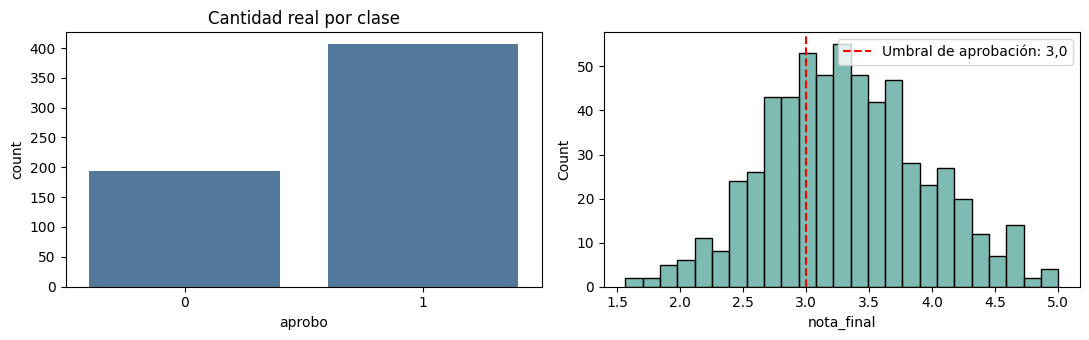

In [7]:
print('Nulos por columna:');print(datos.isna().sum().to_string())
print('\nResumen de cuatro variables:')
display(datos[['promedio_anterior','horas_estudio_semana','asistencia_pct','nota_final']].describe().round(3))
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
sns.countplot(data=datos,x='aprobo',ax=axs[0],color='#467aa6')
axs[0].set_title('Cantidad real por clase')
sns.histplot(data=datos,x='nota_final',bins=25,ax=axs[1],color='#53a49a')
axs[1].axvline(3,color='red',ls='--',label='Umbral de aprobación: 3,0')
axs[1].legend();plt.tight_layout();plt.show()

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> En la tabla `describe()`, **count** es el número de valores no faltantes, **mean** la media, **std** la desviación estándar, **25%, 50% y 75%** los cuartiles, y **min/max** los extremos observados. En la gráfica izquierda, la altura de cada barra es un número de estudiantes, no una tasa de acierto. La línea roja de la derecha corresponde al criterio **real de aprobación** 3,0: **no debe confundirse** con el umbral de probabilidad 0,50 que se aplicará después al clasificador.

## 8. Separar datos ANTES de ajustar el modelo

Una evaluación confiable exige que los datos de prueba no intervengan en el cálculo de los coeficientes ni en el escalado. Se utiliza `train_test_split` con **20 % de prueba** y `stratify=y` para preservar aproximadamente las proporciones de ambas clases en entrenamiento y prueba. `Pipeline` aprenderá la estandarización **solo con entrenamiento**.

In [8]:
X=datos[columnas_x]
y=datos['aprobo']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42,stratify=y)
print('Entrenamiento:',X_train.shape,'Prueba:',X_test.shape)
print('Distribución en entrenamiento:');print(y_train.value_counts().sort_index())
print('Distribución en prueba:');print(y_test.value_counts().sort_index())
print('Proporción clase 1 en entrenamiento:',round(y_train.mean(),4))
print('Proporción clase 1 en prueba:',round(y_test.mean(),4))

Entrenamiento: (480, 6) Prueba: (120, 6)
Distribución en entrenamiento:
aprobo
0    155
1    325
Name: count, dtype: int64
Distribución en prueba:
aprobo
0    39
1    81
Name: count, dtype: int64
Proporción clase 1 en entrenamiento: 0.6771
Proporción clase 1 en prueba: 0.675


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> `(480, 6)` significa **480 estudiantes para ajustar coeficientes y seis predictores**; `(120, 6)` corresponde a **120 estudiantes de prueba** con las mismas seis variables. `stratify=y` permite que la prevalencia de aprobación sea similar en ambas partes, sin garantizar idéntico número absoluto. Es crucial que las 120 etiquetas reales de prueba no se usen para aprender los parámetros.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Reparto concreto:** en entrenamiento hay 155 negativos + 325 positivos = 480; en prueba 39 negativos + 81 positivos = 120. La clase positiva representa 325/480=67,71 % en entrenamiento y 81/120=67,50 % en prueba. Los números diferentes de clase 1 son compatibles con la estratificación aproximada, no significan pérdida de datos.

## 9. Entrenar regresión logística y obtener probabilidades

`LogisticRegression()` aprende una combinación lineal de atributos y la transforma con la sigmoide en probabilidades entre 0 y 1. `fit()` aprende parámetros con los 480 datos de entrenamiento; `predict_proba()` calcula probabilidades para los 120 casos nuevos; `predict()` convierte esas probabilidades en etiquetas usando la regla predeterminada del clasificador, equivalente al umbral 0,50 en este problema binario.

`StandardScaler` se ajusta dentro del `Pipeline` para evitar usar información de prueba en el preprocesamiento.

In [9]:
modelo=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1500,random_state=42))
modelo.fit(X_train,y_train)
prob_test=modelo.predict_proba(X_test)[:,1]
pred_test=modelo.predict(X_test)
print('Número de probabilidades:',len(prob_test))
print('Primeras 10 probabilidades de aprobar:',np.round(prob_test[:10],4))
print('Primeras 10 predicciones binarias:',pred_test[:10])
print('Primeras 10 etiquetas reales:',y_test.to_numpy()[:10])

Número de probabilidades: 120
Primeras 10 probabilidades de aprobar: [0.996  0.7608 0.9436 0.971  0.9381 0.9785 0.766  0.9366 0.9076 0.167 ]
Primeras 10 predicciones binarias: [1 1 1 1 1 1 1 1 1 0]
Primeras 10 etiquetas reales: [1 1 1 0 1 1 0 1 1 0]


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> La salida contiene **120 probabilidades** y 120 etiquetas porque hay 120 observaciones de prueba. Una probabilidad de 0,72 significa que el modelo asigna **72 % a la clase 1**, no que «el estudiante aprobará con certeza»; una clase predicha 1 solo significa que la probabilidad rebasó el umbral configurado. Las primeras 10 filas **no bastan para conocer el rendimiento completo**: necesitamos cruzar todas las 120 predicciones con las 120 etiquetas reales.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Interpretación de la primera salida:** la primera probabilidad es aproximadamente 0,9960, por lo que a corte 0,50 se predice 1. La décima es 0,1670, por lo que se predice 0. Las probabilidades representan las estimaciones del modelo para esos registros; la columna de etiquetas reales permite verificar después si dichas decisiones coinciden.

## 10. Construir la matriz real de la regresión logística

Esta será la matriz central del caso. Al igual que en el ejemplo de 20, las filas son valores reales y las columnas son predicciones. `labels=[0,1]` evita ambigüedad en el orden.

Matriz de prueba:
[[27 12]
 [12 69]]
VN=27 | FP=12 | FN=12 | VP=69 | Total=120


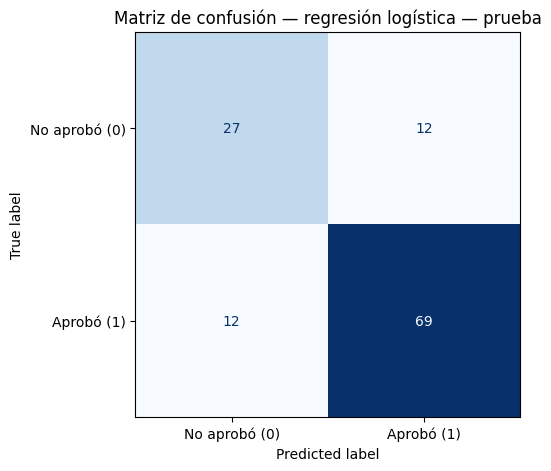

In [10]:
cm=confusion_matrix(y_test,pred_test,labels=[0,1])
tn,fp,fn,tp=cm.ravel()
print('Matriz de prueba:');print(cm)
print(f'VN={tn} | FP={fp} | FN={fn} | VP={tp} | Total={cm.sum()}')
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm,display_labels=['No aprobó (0)','Aprobó (1)']).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
ax.set_title('Matriz de confusión — regresión logística — prueba')
plt.show()

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> La diagonal contiene los **aciertos**: VN y VP. Las otras dos posiciones contienen los **errores**: FP y FN. Al sumar las cuatro celdas debe salir **120**, porque cada estudiante de prueba pertenece exactamente a una celda. Para interpretar **FN**, lee la fila real `Aprobó (1)` y la columna predicha `No aprobó (0)`; para **FP**, haz lo contrario. **La matriz no informa automáticamente qué error es más grave**: depende de las consecuencias del caso de uso.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Resultado exacto del modelo:** `[[27,12],[12,69]]`. Hay **27 verdaderos negativos** (no aprobó y se predijo no aprobó), **12 falsos positivos** (no aprobó pero se predijo aprobó), **12 falsos negativos** (aprobó pero se predijo no aprobó) y **69 verdaderos positivos** (aprobó y se predijo aprobó). Se evaluaron 39 negativos reales (27+12) y 81 positivos reales (12+69). Hubo 96 aciertos (27+69), 24 errores (12+12): 96/120=80 % de accuracy. **Las dos categorías de error tienen aquí el mismo conteo, pero no necesariamente el mismo costo.**

## 11. Métricas del modelo real: todas calculadas desde la matriz

La matriz permite reproducir las métricas que la biblioteca devuelve. Hacer ambos caminos ayuda a comprender por qué una métrica puede subir mientras otra baja.

In [11]:
resumen=pd.Series({
 'Exactitud (accuracy)':(tp+tn)/cm.sum(),
 'Precisión clase 1':tp/(tp+fp) if (tp+fp) else np.nan,
 'Sensibilidad / recall clase 1':tp/(tp+fn) if (tp+fn) else np.nan,
 'Especificidad clase 0':tn/(tn+fp) if (tn+fp) else np.nan,
 'FPR':fp/(fp+tn) if (fp+tn) else np.nan,
 'FNR':fn/(fn+tp) if (fn+tp) else np.nan,
 'F1 clase 1':f1_score(y_test,pred_test),
 'Exactitud balanceada':balanced_accuracy_score(y_test,pred_test),
 'ROC-AUC (probabilidades)':roc_auc_score(y_test,prob_test),
 'Average precision (probabilidades)':average_precision_score(y_test,prob_test)})
display(resumen.to_frame('Valor').round(4))
print('\nReporte completo de clasificación:')
print(classification_report(y_test,pred_test,target_names=['No aprobó','Aprobó'],digits=4,zero_division=0))

,Valor
Exactitud (accuracy),0.8000
Precisión clase 1,0.8519
Sensibilidad / recall clase 1,0.8519
Especificidad clase 0,0.6923
FPR,0.3077
FNR,0.1481
F1 clase 1,0.8519
Exactitud balanceada,0.7721
ROC-AUC (probabilidades),0.8639
Average precision (probabilidades),0.9253



Reporte completo de clasificación:
              precision    recall  f1-score   support

   No aprobó     0.6923    0.6923    0.6923        39
      Aprobó     0.8519    0.8519    0.8519        81

    accuracy                         0.8000       120
   macro avg     0.7721    0.7721    0.7721       120
weighted avg     0.8000    0.8000    0.8000       120



> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> Las primeras métricas se obtienen de **conteos de la matriz**; `ROC-AUC` y `average precision` requieren las **probabilidades originales**, no una única matriz de umbral 0,50. `accuracy` cuenta aciertos sobre 120. `precision` divide VP entre todas las predicciones positivas; `recall` divide VP entre positivos reales. `balanced_accuracy` promedia el recall de las clases 0 y 1, para no premiar automáticamente a una clase mayoritaria. En `classification_report`, `support` son los casos **reales** de cada clase y `macro avg`/`weighted avg` usan reglas diferentes para agregar. **Un ROC-AUC favorable no garantiza que un umbral concreto tenga recall satisfactorio**.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Todas las métricas concretas:** accuracy `(27+69)/120=0,8000`; precision de aprobado `69/(69+12)=0,8519`; recall de aprobado `69/(69+12)=0,8519`; especificidad `27/(27+12)=0,6923`; FPR `12/39=0,3077`; FNR `12/81=0,1481`; F1 de clase 1 `0,8519` (coinciden precision y recall por esta configuración). Balanced accuracy `(0,6923+0,8519)/2=0,7721`. ROC-AUC `0,8639` y AP `0,9253` se calculan desde **probabilidades**, por lo que no salen de una única matriz 2×2. **El modelo falla en 12 de 39 negativos (30,77 %) y 12 de 81 positivos (14,81 %): el mismo número absoluto no implica la misma tasa de error.**

## 12. Normalización por filas: tasas condicionadas a la clase real

La matriz de conteos y la matriz normalizada **responden preguntas distintas**. `normalize='true'` divide cada fila por su total: la primera fila responde cómo se clasificaron los negativos reales y la segunda cómo se clasificaron los positivos reales. Cada fila suma 1, salvo clases sin casos.

Matriz de conteos:
[[27 12]
 [12 69]]
Matriz normalizada por clase real:
[[0.6923 0.3077]
 [0.1481 0.8519]]


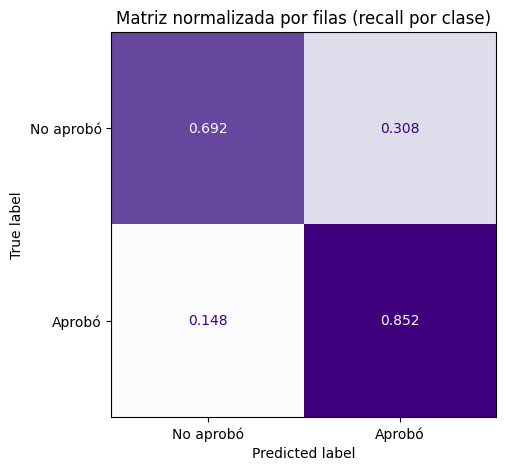

In [12]:
cm_norm=confusion_matrix(y_test,pred_test,labels=[0,1],normalize='true')
print('Matriz de conteos:');print(cm)
print('Matriz normalizada por clase real:');print(np.round(cm_norm,4))
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm_norm,display_labels=['No aprobó','Aprobó']).plot(ax=ax,cmap='Purples',colorbar=False,values_format='.3f')
ax.set_title('Matriz normalizada por filas (recall por clase)')
plt.show()

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> La **celda inferior derecha** de la matriz normalizada es el **recall de la clase 1**: `VP/(VP+FN)`. La **celda superior izquierda** es la **especificidad**, también recall de clase 0: `VN/(VN+FP)`. Las dos celdas restantes representan tasas de error específicas: **FPR** arriba a la derecha y **FNR** abajo a la izquierda. No confundas `0,80` con 80 estudiantes: en esta matriz significa **80 % de la fila respectiva**.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Resultado de la normalización:** primera fila `[0,6923,0,3077]`: de los 39 estudiantes que realmente no aprobaron, 69,23 % se reconoció y 30,77 % se confundió con aprobación. Segunda fila `[0,1481,0,8519]`: de los 81 que sí aprobaron, 14,81 % fue pasado por alto y 85,19 % fue reconocido. Cada fila suma 1; **no** hay que sumar porcentajes entre filas para calcular accuracy.

## 13. Probabilidades frente a clases: ¿qué pasa si movemos el umbral?

Una misma regresión logística puede generar muchas matrices de confusión distintas. La **probabilidad estimada no cambia** al mover el umbral; lo que cambia es la decisión de clasificar como 1.

- Con **umbral bajo**, suele aumentar la sensibilidad, pero también pueden crecer los falsos positivos.
- Con **umbral alto**, suelen reducirse los falsos positivos, pero pueden aumentar los falsos negativos.

Esto no significa que haya que escoger automáticamente 0,50, 0,30 o 0,70. El umbral se define por costos, finalidad, calibración y validación, **nunca ajustándolo repetidamente sobre la prueba final**.

In [13]:
filas=[]
for umbral in [0.20,0.35,0.50,0.65,0.80]:
 p=(prob_test>=umbral).astype(int)
 a,b,c,d=confusion_matrix(y_test,p,labels=[0,1]).ravel()
 filas.append({'Umbral':umbral,'VN':a,'FP':b,'FN':c,'VP':d,
  'Accuracy':accuracy_score(y_test,p),'Precision':precision_score(y_test,p,zero_division=0),
  'Recall':recall_score(y_test,p,zero_division=0),'F1':f1_score(y_test,p,zero_division=0)})
tabla_umbrales=pd.DataFrame(filas)
display(tabla_umbrales.round(4))

,Umbral,VN,FP,FN,VP,Accuracy,Precision,Recall,F1
0,0.20,10,29,0,81,0.7583,0.7364,1.0000,0.8482
1,0.35,21,18,7,74,0.7917,0.8043,0.9136,0.8555
2,0.50,27,12,12,69,0.8000,0.8519,0.8519,0.8519
3,0.65,30,9,18,63,0.7750,0.8750,0.7778,0.8235
4,0.80,35,4,28,53,0.7333,0.9298,0.6543,0.7681


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> **Lee la tabla horizontalmente:** para un mismo umbral, `VN+FP+FN+VP=120`. **Léela verticalmente:** al elevar el umbral, ningún individuo pasa de predicción 0 a 1, por lo que el número de predicciones positivas no puede aumentar; en general `VP` y `FP` no aumentan, mientras `FN` y `VN` no disminuyen. El `Recall` suele descender y la `Precision` no tiene obligación matemática de aumentar siempre. **Importante:** estos cinco umbrales se exploran didácticamente en los mismos datos de prueba; para seleccionar un umbral real sería obligatorio utilizar entrenamiento/validación.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Comparación numérica de cinco umbrales:** a `0,20`, VN=10, FP=29, FN=0 y VP=81: sensibilidad 100 %, pero 29 falsas alarmas. A `0,35`, VN=21, FP=18, FN=7 y VP=74: recall 91,36 %. A `0,50`, VN=27, FP=12, FN=12 y VP=69: accuracy 80 %. A `0,65`, VN=30, FP=9, FN=18 y VP=63: precision 87,50 %. A `0,80`, VN=35, FP=4, FN=28 y VP=53: precision 92,98 %, pero recall solo 65,43 %. Este intercambio entre FP y FN es la razón práctica de estudiar el umbral. El mayor accuracy de **estos cinco** es 0,80 a corte 0,50; eso no prueba que sea el mejor umbral de población ni autoriza ajustarlo con prueba.

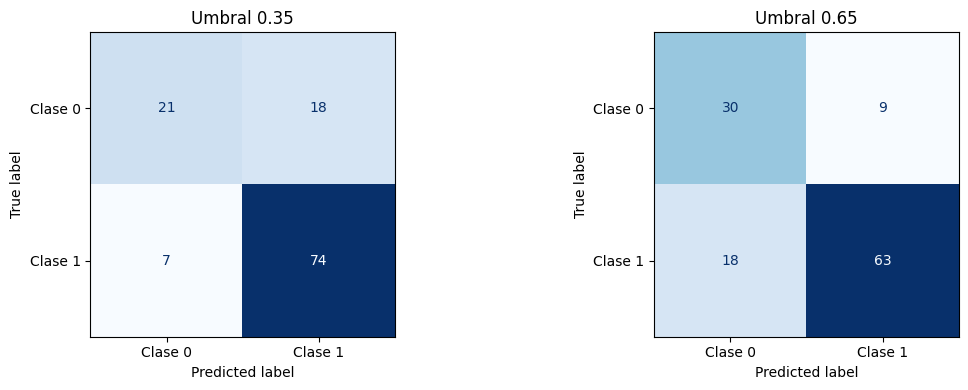

In [14]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for umbral in [0.35,0.65]:
 pred=(prob_test>=umbral).astype(int)
 mat=confusion_matrix(y_test,pred,labels=[0,1])
 j=0 if umbral==0.35 else 1
 ConfusionMatrixDisplay(mat,display_labels=['Clase 0','Clase 1']).plot(ax=ax[j],cmap='Blues',colorbar=False,values_format='d')
 ax[j].set_title(f'Umbral {umbral:.2f}')
plt.tight_layout();plt.show()

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> **Ambas gráficas evalúan el mismo modelo sobre los mismos 120 registros**; solo cambió el corte aplicado a las probabilidades. Compara la **celda FP** (arriba a la derecha) y la **FN** (abajo a la izquierda). Si se prioriza detectar positivos, un umbral más bajo puede ser útil; si se prioriza evitar alarmas falsas, un corte mayor podría ser preferible. **Elegir entre ellos exige conocer los costos de FP y FN.**

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Comparación de las dos matrices:** umbral 0,35 produce `[[21,18],[7,74]]`; umbral 0,65 produce `[[30,9],[18,63]]`. Al subir el corte, los FP caen de 18 a 9 (nueve menos), mientras los FN suben de 7 a 18 (once más). El costo relativo de ambos errores determina cuál de los dos escenarios es preferible; no existe una respuesta universal.

## 14. ¿Qué significa «el modelo mejora»? La trampa del accuracy en clases desbalanceadas

Construimos un conjunto simulado distinto: 95 negativos y cinco positivos. Un modelo que predice todo 0 obtiene **95 % de exactitud**, pero **no detecta ningún positivo**. Por ello, la exactitud no es suficiente cuando una clase es rara o tiene un costo alto pasarla por alto.

Matriz con 95 negativos y 5 positivos:
[[95  0]
 [ 5  0]]
Accuracy: 0.95
Recall clase 1: 0.0
Precision clase 1: 0.0
Balanced accuracy: 0.5


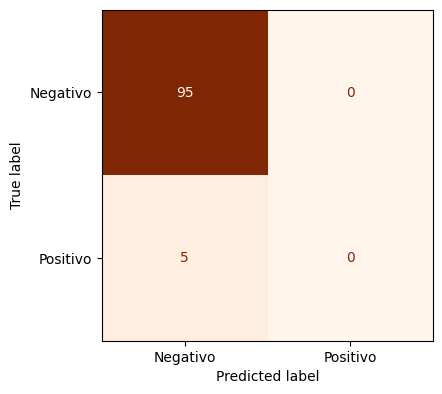

In [15]:
y_imb=np.array([0]*95+[1]*5)
pred_todo_cero=np.zeros_like(y_imb)
mat_imb=confusion_matrix(y_imb,pred_todo_cero,labels=[0,1])
print('Matriz con 95 negativos y 5 positivos:');print(mat_imb)
print('Accuracy:',accuracy_score(y_imb,pred_todo_cero))
print('Recall clase 1:',recall_score(y_imb,pred_todo_cero,zero_division=0))
print('Precision clase 1:',precision_score(y_imb,pred_todo_cero,zero_division=0))
print('Balanced accuracy:',balanced_accuracy_score(y_imb,pred_todo_cero))
fig,ax=plt.subplots(figsize=(5.5,4.3))
ConfusionMatrixDisplay(mat_imb,display_labels=['Negativo','Positivo']).plot(ax=ax,cmap='Oranges',colorbar=False)
plt.show()

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> La matriz es `[[95,0],[5,0]]`: 95 **VN**, cero FP, cinco **FN**, cero VP. **Accuracy=95/100=0,95**, cifra llamativamente alta. Pero **recall=0/5=0**: no se encontró ningún positivo. La precisión de clase 1 está matemáticamente indefinida porque el clasificador **no predijo ningún positivo**; `zero_division=0` reporta cero por convención computacional, no porque haya diez intentos fallidos. **Balanced accuracy=(1+0)/2=0,50**, mostrando un desempeño trivial entre clases. Este ejemplo explica por qué nunca se debe celebrar 95 % de accuracy sin revisar la matriz.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Paradoja explícita:** un accuracy de 0,95 parece excelente, pero la matriz `[[95,0],[5,0]]` evidencia cinco positivos reales ignorados. Recall=0/5=0. Balanced accuracy `(1+0)/2=0,50`. Un modelo que no predice positivos no permite calcular la precisión de la clase 1 por su fórmula original `0/(0+0)`; la biblioteca la reporta 0 por la configuración `zero_division=0`. Esto no debe llamarse «95 % de sensibilidad».

## 15. Matriz de confusión y costos: un escenario de inspección industrial

Supongamos que `1` significa pieza defectuosa. En un ejemplo **hipotético**, una falsa alarma cuesta 2 unidades monetarias por revisión y una falla no detectada cuesta 20 por devolución. No son costos reales de ninguna planta. La prioridad puede cambiar porque un FN resulta diez veces más costoso que un FP.

> Los costos dependen del contexto real: seguridad, cumplimiento, pérdida económica, capacidad de inspección y efectos sobre personas.

In [16]:
tabla_costos=tabla_umbrales[['Umbral','FP','FN','Accuracy','Recall','Precision']].copy()
costo_fp=2;costo_fn=20
tabla_costos['Costo_FP']=tabla_costos['FP']*costo_fp
tabla_costos['Costo_FN']=tabla_costos['FN']*costo_fn
tabla_costos['Costo_total_hipotetico']=tabla_costos['Costo_FP']+tabla_costos['Costo_FN']
display(tabla_costos.round(3))
print('Umbral de menor costo en estos cinco valores de prueba (solo ejemplo didáctico):',
      tabla_costos.loc[tabla_costos.Costo_total_hipotetico.idxmin(),'Umbral'])

,Umbral,FP,FN,Accuracy,Recall,Precision,Costo_FP,Costo_FN,Costo_total_hipotetico
0,0.20,29,0,0.758,1.000,0.736,58,0,58
1,0.35,18,7,0.792,0.914,0.804,36,140,176
2,0.50,12,12,0.800,0.852,0.852,24,240,264
3,0.65,9,18,0.775,0.778,0.875,18,360,378
4,0.80,4,28,0.733,0.654,0.930,8,560,568


Umbral de menor costo en estos cinco valores de prueba (solo ejemplo didáctico): 0.2


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> `Costo_FP=FP×2` y `Costo_FN=FN×20`. La columna final **suma ambas pérdidas hipotéticas**. Aunque dos umbrales tengan exactitudes similares, pueden producir costos muy diferentes porque sus tipos de error cambian. **La cifra ganadora aquí NO debe adoptarse como umbral validado**: se ha calculado con las etiquetas del conjunto de prueba para ilustrar la lógica; en un sistema real se optimiza en validación y se confirma una sola vez sobre prueba final.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Cálculo de costos con cifras reales de la ejecución (costos inventados para el ejemplo):** umbral 0,20: `29×2+0×20=58`; umbral 0,35: `18×2+7×20=176`; umbral 0,50: `12×2+12×20=264`; umbral 0,65: `9×2+18×20=378`; umbral 0,80: `4×2+28×20=568`. Bajo esta función de costos, el menor entre los umbrales explorados es 0,20. **No** es un umbral final metodológicamente validado, porque aquí se utilizaron las etiquetas de prueba para el ejercicio ilustrativo.

## 16. Comparación con un clasificador que siempre pronostica la clase más frecuente

`DummyClassifier(strategy='most_frequent')` no aprende relaciones entre las seis variables: ignora sus valores para predecir siempre la clase más común en entrenamiento. Su función es establecer una **línea base**. Un modelo sofisticado debe justificar sus mejoras frente a soluciones simples.

In [17]:
dummy=DummyClassifier(strategy='most_frequent')
dummy.fit(X_train,y_train)
pred_dummy=dummy.predict(X_test)
comparacion=pd.DataFrame([
 {'Modelo':'Siempre clase mayoritaria','Accuracy':accuracy_score(y_test,pred_dummy),'Balanced accuracy':balanced_accuracy_score(y_test,pred_dummy),'F1 clase 1':f1_score(y_test,pred_dummy,zero_division=0)},
 {'Modelo':'Regresión logística','Accuracy':accuracy_score(y_test,pred_test),'Balanced accuracy':balanced_accuracy_score(y_test,pred_test),'F1 clase 1':f1_score(y_test,pred_test,zero_division=0)}])
display(comparacion.round(4))
print('Matriz dummy:',confusion_matrix(y_test,pred_dummy,labels=[0,1]),sep='\n')

,Modelo,Accuracy,Balanced accuracy,F1 clase 1
0,Siempre clase mayoritaria,0.675,0.5000,0.8060
1,Regresión logística,0.800,0.7721,0.8519


Matriz dummy:
[[ 0 39]
 [ 0 81]]


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> El clasificador de referencia puede lograr una exactitud aparentemente elevada **simplemente por la prevalencia** de una clase. Observa la matriz dummy: si siempre pronostica 1, tendrá **VN=0 y FN=0**, y todos los 0 reales serán FP. La regresión logística debería juzgarse por si mejora métricas relevantes para la finalidad, no por llevar un nombre más complejo. `F1` aquí mide específicamente la clase 1, no la clase 0.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Resultados comparados:** Dummy predice siempre la clase 1, porque es mayoritaria. Su matriz es `[[0,39],[0,81]]`: 81 VP, 39 FP, cero VN, cero FN; accuracy `81/120=0,675`, balanced accuracy `(0+1)/2=0,50` y F1 de clase 1 `0,8060`. La logística logra accuracy `0,8000`, balanced accuracy `0,7721` y F1 `0,8519`. La matriz muestra que la logística también reconoce 27 estudiantes que no aprobaron; el dummy no reconoce ninguno.

## 17. Curva ROC y curva precisión-recall: más allá de una sola matriz

Una matriz depende de un **umbral**. Las curvas evalúan varios umbrales. La **ROC** grafica sensibilidad (TPR) contra tasa de falsos positivos (FPR). La **PR** grafica precision frente a recall. `ROC-AUC` resume la capacidad de ordenar casos positivos por encima de negativos; **no** es porcentaje de clasificaciones correctas. `Average precision` resume el compromiso de precision–recall y debe leerse con la prevalencia como referencia.

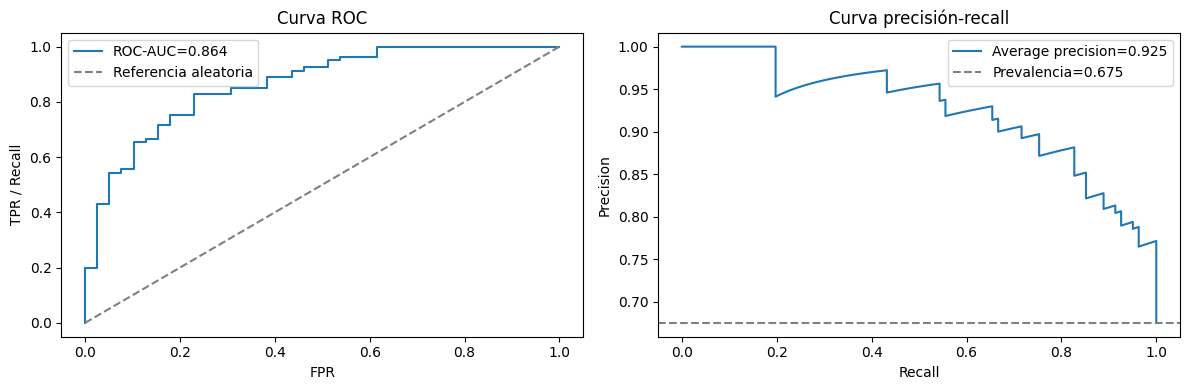

ROC-AUC: 0.8639 Average precision: 0.9253


In [18]:
fpr,tpr,roc_thr=roc_curve(y_test,prob_test)
pr,rec,pr_thr=precision_recall_curve(y_test,prob_test)
auc=roc_auc_score(y_test,prob_test)
ap=average_precision_score(y_test,prob_test)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(fpr,tpr,label=f'ROC-AUC={auc:.3f}')
ax[0].plot([0,1],[0,1],'--',color='gray',label='Referencia aleatoria')
ax[0].set(xlabel='FPR',ylabel='TPR / Recall',title='Curva ROC');ax[0].legend()
ax[1].plot(rec,pr,label=f'Average precision={ap:.3f}')
ax[1].axhline(y_test.mean(),ls='--',color='gray',label=f'Prevalencia={y_test.mean():.3f}')
ax[1].set(xlabel='Recall',ylabel='Precision',title='Curva precisión-recall');ax[1].legend()
plt.tight_layout();plt.show()
print('ROC-AUC:',round(auc,4),'Average precision:',round(ap,4))

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> La ROC muestra el compromiso entre **detectar positivos** y **generar falsos positivos**. La diagonal indica clasificación sin discriminación útil en promedio. La curva PR resulta especialmente informativa cuando interesa la clase positiva y puede haber desbalance. La línea horizontal en PR usa la **prevalencia de positivos en prueba**, no una precisión constante que todo modelo real alcance. ROC-AUC y AP son resúmenes sobre umbrales; para una decisión concreta todavía hay que elegir umbral y revisar su matriz.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Interpretación específica:** ROC-AUC=0,8639 es la capacidad resumida para ordenar positivos por encima de negativos cuando se varía el umbral; no quiere decir «86,39 % de estudiantes correctos». AP=0,9253 resume la curva de precisión-recall. El nivel de referencia de la curva PR es la prevalencia de aprobados de prueba, **81/120=0,675**. Estas dos métricas no describen un único umbral de clasificación.

## 18. Comprobar la estabilidad mediante validación cruzada estratificada

Una sola matriz de prueba depende del reparto particular 80/20. Con `StratifiedKFold(n_splits=5)` obtenemos cinco grupos de validación, preservando aproximadamente las proporciones de las dos clases; en cada pliegue se vuelve a ajustar todo el `Pipeline` usando solo los otros cuatro grupos. `cross_val_predict` permite obtener **una predicción fuera de pliegue por cada fila de entrenamiento**.

**Advertencia:** la matriz agregada fuera de pliegue no es la media aritmética de cinco matrices normalizadas; es la suma de los conteos obtenidos sobre todas las muestras retenidas una vez.

Total de estudiantes con predicción fuera de pliegue: 480
Matriz agregada OOF:
[[ 92  63]
 [ 40 285]]
Accuracy OOF: 0.7854
Recall OOF: 0.8769
Precision OOF: 0.819


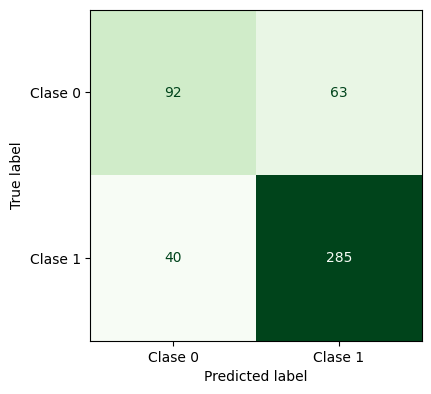

In [19]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
pred_oof=cross_val_predict(modelo,X_train,y_train,cv=cv,method='predict')
mat_oof=confusion_matrix(y_train,pred_oof,labels=[0,1])
print('Total de estudiantes con predicción fuera de pliegue:',len(pred_oof))
print('Matriz agregada OOF:');print(mat_oof)
print('Accuracy OOF:',round(accuracy_score(y_train,pred_oof),4))
print('Recall OOF:',round(recall_score(y_train,pred_oof),4))
print('Precision OOF:',round(precision_score(y_train,pred_oof),4))
fig,ax=plt.subplots(figsize=(5.5,4.3))
ConfusionMatrixDisplay(mat_oof,display_labels=['Clase 0','Clase 1']).plot(ax=ax,cmap='Greens',colorbar=False)
plt.show()

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> Hay **480 predicciones fuera de pliegue**, una por cada registro del conjunto de entrenamiento: cada predicción se hizo con un modelo que no ajustó parámetros usando esa fila. La matriz suma **480**, no 120. Es válido usar esta matriz para estudiar comportamiento de validación, pero **no reemplaza** la matriz final de los 120 casos de prueba completamente separados. Las matrices difieren porque corresponden a muestras y modelos ajustados distintos.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Lectura de validación cruzada:** la matriz OOF `[[92,63],[40,285]]` suma 480. Sobre los 155 negativos reales, 92 se identificaron correctamente y 63 se confundieron; sobre los 325 positivos, se detectaron 285 y se omitieron 40. Accuracy `(92+285)/480=0,7854`; recall `285/(285+40)=0,8769`; precision `285/(285+63)=0,8190`. Esta es una evaluación fuera de pliegue sobre **entrenamiento**, diferente de la matriz independiente de prueba `[[27,12],[12,69]]`.

## 19. Matriz multiclase: tres categorías en vez de dos

En un problema de tres clases, por ejemplo `bajo`, `medio`, `alto`, la matriz tiene 3×3 posiciones. Cada fila es una clase real y cada columna una clase predicha. La **diagonal contiene los aciertos** y todas las demás celdas, errores de confusión entre pares de clases. Para calcular precisión y recall de una clase concreta se usa enfoque **uno contra el resto**.

Matriz multiclase:
[[4 2 0]
 [1 5 1]
 [0 2 5]]
Total: 20 Aciertos: 14 Errores: 6

Reporte por clase:
              precision    recall  f1-score   support

        Bajo     0.8000    0.6667    0.7273         6
       Medio     0.5556    0.7143    0.6250         7
        Alto     0.8333    0.7143    0.7692         7

    accuracy                         0.7000        20
   macro avg     0.7296    0.6984    0.7072        20
weighted avg     0.7261    0.7000    0.7062        20



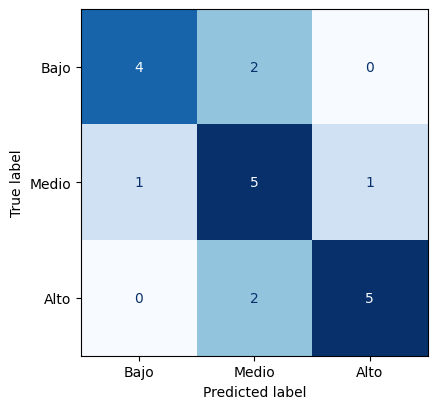

In [20]:
clases=['Bajo','Medio','Alto']
y_true_multi=['Bajo']*6+['Medio']*7+['Alto']*7
y_pred_multi=['Bajo']*4+['Medio']*2+['Bajo']+['Medio']*5+['Alto']+['Medio']*2+['Alto']*5
cm_multi=confusion_matrix(y_true_multi,y_pred_multi,labels=clases)
print('Matriz multiclase:');print(cm_multi)
print('Total:',cm_multi.sum(),'Aciertos:',np.trace(cm_multi),'Errores:',cm_multi.sum()-np.trace(cm_multi))
print('\nReporte por clase:')
print(classification_report(y_true_multi,y_pred_multi,labels=clases,zero_division=0,digits=4))
fig,ax=plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay(cm_multi,display_labels=clases).plot(ax=ax,cmap='Blues',colorbar=False)
plt.show()

> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> La suma de las nueve celdas es **20 observaciones**. Cada elemento fuera de diagonal identifica **qué clase real fue confundida con cuál clase predicha**. Para una clase (por ejemplo `Alto`), `recall` se calcula dividiendo la diagonal de su fila entre la suma de esa fila; `precision`, dividiendo la diagonal de su columna entre la suma de esa columna. En multiclase no hay un único FP o FN sin indicar **qué clase se toma como positiva**.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Matriz multiclase exacta:** `[[4,2,0],[1,5,1],[0,2,5]]`, total 20. Para `Bajo`, recall `4/6=0,6667` y precision `4/(4+1+0)=0,8000`. Para `Medio`, recall `5/7=0,7143` y precision `5/(2+5+2)=0,5556`. Para `Alto`, recall `5/7=0,7143` y precision `5/(0+1+5)=0,8333`. La exactitud global es `(4+5+5)/20=0,70`. El apoyo por clase es 6, 7 y 7, respectivamente.

## 20. Ejemplo manual de una predicción individual: de la probabilidad a la celda

Una vez entrenado un clasificador, cada estudiante tiene una etiqueta real, una probabilidad de clase 1 y una clase predicha. La matriz solo cuenta cuántas filas corresponden a cada combinación. Reconstruiremos las primeras 12 filas de prueba con una columna de explicación automática.

In [21]:
detalle=pd.DataFrame({'Real':y_test.to_numpy(),'Probabilidad_aprobar':prob_test,'Predicha_0_50':pred_test})
detalle['Tipo']=np.select([
 (detalle.Real==0)&(detalle.Predicha_0_50==0),
 (detalle.Real==0)&(detalle.Predicha_0_50==1),
 (detalle.Real==1)&(detalle.Predicha_0_50==0)],['VN','FP','FN'],default='VP')
display(detalle.head(12).round(4))
print('Conteos desde tabla de detalle:')
print(detalle['Tipo'].value_counts().reindex(['VN','FP','FN','VP']))
assert detalle['Tipo'].value_counts().sum()==120

,Real,Probabilidad_aprobar,Predicha_0_50,Tipo
0,1,0.9960,1,VP
1,1,0.7608,1,VP
2,1,0.9436,1,VP
3,0,0.9710,1,FP
4,1,0.9381,1,VP
5,1,0.9785,1,VP
6,0,0.7660,1,FP
7,1,0.9366,1,VP
8,1,0.9076,1,VP
9,0,0.1670,0,VN


Conteos desde tabla de detalle:
Tipo
VN    27
FP    12
FN    12
VP    69
Name: count, dtype: int64


> **INTERPRETACIÓN DE LA SALIDA ANTERIOR — PARA EXPLICAR EN CLASE**
>
> En cada fila, `Real` es el resultado observado y `Probabilidad_aprobar` es lo que estimó el modelo. `Predicha_0_50` vale 1 si probabilidad ≥ 0,50 y 0 en caso contrario. **Tipo** se determina comparando `Real` con `Predicha_0_50`; los conteos completos deben coincidir con la matriz del apartado 10. **No se calcula FN comparando la probabilidad con cero**: los falsos negativos son precisamente observaciones realmente 1 pero predichas 0.

> **LECTURA NUMÉRICA DE ESTA CORRIDA:** **Coherencia verificada:** al clasificar una a una las 120 predicciones, el conteo `VN=27, FP=12, FN=12, VP=69` reproduce exactamente la matriz de la sección 10. Esto demuestra que `confusion_matrix` solo resume las decisiones individuales del modelo bajo la convención establecida. Para un registro, una probabilidad alta no cambia su etiqueta real: únicamente modifica la etiqueta predicha al aplicar el umbral.

## 21. Guía docente: ¿qué deberías preguntar después de ver una matriz?

1. ¿Qué es exactamente la clase 1? ¿«Positivo» significa aprobar, reprobar o presentar una falla?
2. ¿Qué contienen las **filas** y qué contienen las **columnas**? ¿Cuál es su orden?
3. ¿Cuántos registros se evaluaron? ¿Coincide con la suma de celdas?
4. ¿Cuántos aciertos y errores hay? ¿Qué tipos de error son?
5. ¿Por qué precisión y sensibilidad tienen **denominadores diferentes**?
6. ¿Qué ocurre si solo miramos accuracy en presencia de clases desbalanceadas?
7. ¿El modelo se evaluó sobre entrenamiento, validación o prueba independiente?
8. ¿Por qué la misma regresión logística presenta matrices distintas con umbrales diferentes?
9. ¿Cuál error sería más costoso en el problema específico? ¿Con qué evidencia asignamos ese costo?
10. ¿Por qué no conviene elegir el umbral directamente sobre el conjunto de prueba?

### Discusión de cierre

**Conclusión metodológica:** una matriz de confusión no «demuestra que un modelo es bueno» por sí sola. Aporta conteos específicos de aciertos y fallos bajo una elección de clase positiva, umbral y muestra de evaluación. Para defender su uso debemos contrastar con línea base, métricas acordes al objetivo, prevalencia, costos, estabilidad y evaluación independiente.

## 22. Referencias bibliográficas verificables (APA 7)

Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters, 27*(8), 861–874. https://doi.org/10.1016/j.patrec.2005.10.010

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://www.jmlr.org/papers/v12/pedregosa11a.html

Scikit-learn developers. (s. f.). *Confusion matrix*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

Scikit-learn developers. (s. f.). *Classification report*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html

**Nota:** el ejercicio de 600 estudiantes es de elaboración sintética; los ejemplos numéricos manuales son didácticos y no constituyen evidencia empírica de poblaciones reales.